In [1]:
import numpy as np
import matplotlib.pyplot as plt
from optical_transmission_system.components import *

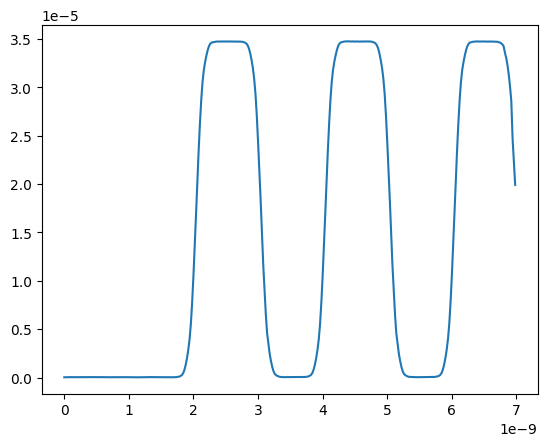

In [11]:
system = System(components=[
    NRZEncoder(sampling_rate=50e9),
    ElectricalLowPassFilter(order=5, cutoff_frequency=3e9),
    AWGN(power=2e-6),
    Transmitter(power=2e-3, linewidth=10e9, frequency_count=128),
    OpticalChannel(attenuation=0.22, length=80, chromatic_dispersion=17),
])

input_signal = DigitalSignal(samples=np.array([0, 0, 1, 0, 1, 0, 1]), sampling_rate=1e-9, data_rate=1e9)
output_signal = system(input_signal)
 
plt.plot(output_signal.time, np.sum(output_signal.samples**2, axis=1, dtype="float32"))

In [12]:
np.sum(output_signal.samples**2) / len(output_signal.samples)

np.float32(1.4517658e-05)

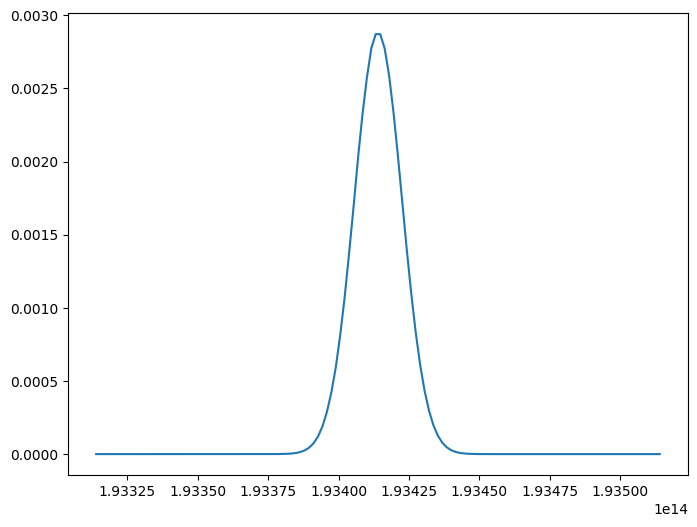

In [4]:
plt.figure(figsize=(8, 6))
plt.plot(output_signal.frequencies, np.sum(output_signal.samples.transpose()**2, axis=1))